# Computational assignment: Modeling and simulation of a vehicle suspension system

**Four-degree-of-freedom heave–pitch model | Newton's second law | Modal analysis | Numerical simulation | Plotly**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/)

> **How to open:** Download this `.ipynb`, follow the badge to Colab, and select **File → Upload notebook**. The badge links to Colab's homepage, not directly to this unhosted file.

### The assignment

Develop, verify, and investigate a numerical model of the vehicle-suspension arrangement shown below. Start from **Newton's second law and the moment equation**; assemble the coupled dynamics, simulate prescribed road excitation, examine the vibration modes, and investigate the consequences of suspension design choices.

**The task is to formulate and investigate the model, not merely to generate plots.** Explain assumptions, signs, choices of numerical methods, and the physical meaning of results.

**Conventions:** Use SI units and consistent coordinate ordering throughout. All figures generated in the solution should be interactive **Plotly** figures, including an animated demonstration of heave–pitch motion. You may use NumPy, SciPy, SymPy, pandas, Plotly, and optionally ipywidgets.

This notebook contains the **question and working areas only**; it intentionally does not contain worked solutions or numerical answers.

## 1. Physical system

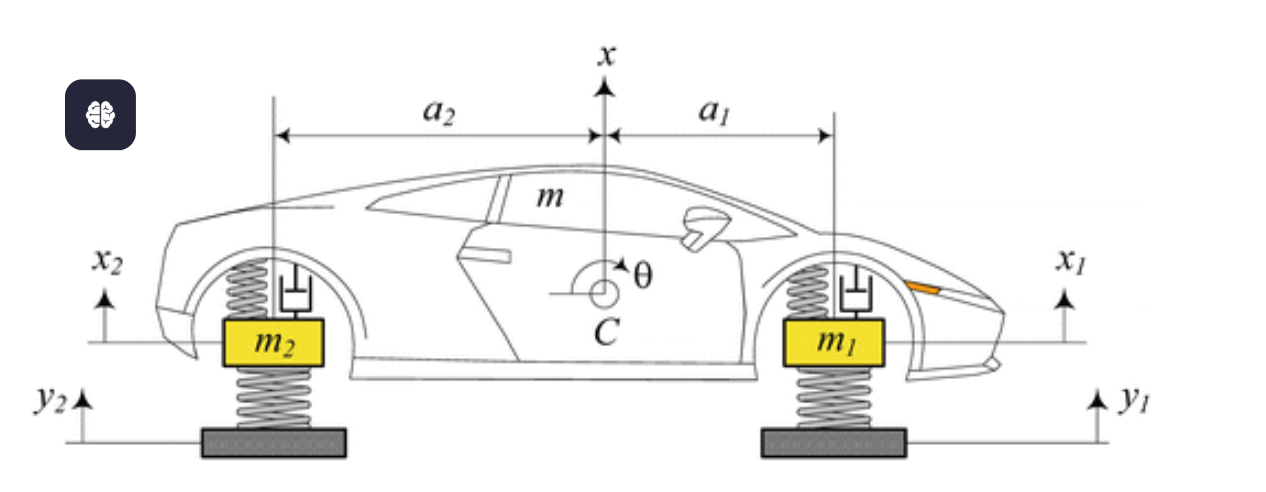

*Use the figure to identify the sprung body, the two unsprung masses, the suspension elements, and the tire/road contact elements.*

### 1.1 Degrees of freedom and assumptions

The rigid vehicle body has mass $m$ and mass moment of inertia $I$ about its center $C$. The front and rear unsprung masses are $m_1$ and $m_2$. The body center is a distance $a_1$ from the front suspension and $a_2$ from the rear suspension. Each of the two suspension units has stiffness $k_s$ and viscous damping $c_s$, and each tire is modeled by stiffness $k_t$ (optional tire damping $c_t$).

Use the generalized displacement vector

$$
X=\begin{bmatrix}y_1&y_2&x&\theta\end{bmatrix}^{T},
$$

where $y_1,y_2$ are the front and rear unsprung displacements, $x$ is the vertical displacement of $C$, and $\theta$ is the pitch angle. Take vertical displacements positive **upward** and pitch positive **clockwise** (the front moves downward for positive $\theta$).

Assume a rigid body with small pitch, linear spring and damping laws, and tire contact maintained throughout. Measure all displacements **from static equilibrium**, so constant gravitational forces are absent from the incremental equations.

**Questions**

1. Explain why four degrees of freedom are sufficient for this planar model. What motions and physical effects are excluded?
2. Express the front and rear body suspension-point displacements in terms of $x$, $\theta$, $a_1$, and $a_2$.
3. Identify the incremental deformation and relative velocity of each suspension element and each tire element, allowing for distinct road elevations $r_1(t)$ and $r_2(t)$.
4. Clearly state the sign conventions for the suspension forces and for externally applied vertical force $f(t)$ and pitch moment $T(t)$.

### 1.2 Numerical data (illustrative vehicle)

Use **these values** for the baseline calculations; they are demonstration parameters, not measurements of a particular vehicle.

| Parameter | Value | Unit |
|:--|--:|:--|
| Sprung mass, $m$ | 1200 | kg |
| Pitch moment of inertia, $I$ | 2100 | kg m$^2$ |
| Front unsprung mass, $m_1$ | 45 | kg |
| Rear unsprung mass, $m_2$ | 45 | kg |
| Distance to front axle, $a_1$ | 1.25 | m |
| Distance to rear axle, $a_2$ | 1.45 | m |
| Each suspension spring, $k_s$ | 28000 | N/m |
| Each tire stiffness, $k_t$ | 190000 | N/m |
| Each suspension damper, $c_s$ | 2200 | N s/m |
| Each tire damper, $c_t$ | 0 | N s/m |

Use the above for all baseline computations, and vary only the named parameter(s) in each later investigation. Set $f=T=0$ except where a direct-force experiment is explicitly requested.

## 2. Derive and assemble the equations of motion (Newton's method)

**Task 2.1 — Force and moment balances.** Draw a schematic force diagram for each unsprung mass and the rigid body. Write the incremental Newton equations for the front and rear unsprung masses, the vertical motion of the body, and the pitch motion of the body about $C$.

- Include relative suspension spring and damper forces, and both road-driven tire forces.
- Show explicitly how $r_i$ and $\dot r_i$ enter the tire forces.
- Confirm the signs of the two pitch-moment contributions.
- Explain how the $c_t=0$ case relates to the basic suspension model.

**Task 2.2 — Matrix formulation.** Assemble the four equations into

$$
M\ddot X+C\dot X+KX=F(t).
$$

Obtain $M$, $C$, $K$, and $F(t)$, including road displacement inputs and any direct force and moment on the sprung body. Construct suitable matrices $B_s$ and $B_t$ mapping generalized displacements to suspension deflections and unsprung displacements. Use them to derive a compact **factorized** representation of the damping and stiffness matrices.

**Task 2.3 — First-order form.** Define $Y=[X^T,\dot X^T]^T$ and obtain an eight-state representation

$$
\dot Y=AY+B_u u+B_r r+B_{\dot r}\dot r,
\qquad u=\begin{bmatrix}f&T\end{bmatrix}^{T},
\qquad r=\begin{bmatrix}r_1&r_2\end{bmatrix}^{T}.
$$

Specify the dimensions of every matrix. Briefly explain why the mass matrix is invertible and identify the physical meaning of the road-input terms.

### 2.4 Mathematical and numerical consistency checks

Using Python, construct the matrices and verify:

1. $M$ is symmetric and positive definite.
2. $C$ and $K$ are symmetric, and their relevant definiteness properties agree with the physical model.
3. The directly expanded element-by-element equations agree with the factorized matrix formulation (consider using SymPy).
4. The input vector vanishes when $r=\dot r=f=T=0$.

Present $K$ and $C$ with **Plotly heatmaps**, including row/column labels. Briefly explain the sign and magnitude patterns of their coupling entries. Remember that entries involving $\theta$ have coordinate-dependent units.

## 3. Python implementation

Write reusable, clearly named functions for:

- constructing $M$, $C$, $K$, $B_s$, and $B_t$ from a parameter set;
- evaluating road height and road velocity at each tire;
- evaluating the right-hand side of the eight-state differential equation;
- integrating the system and extracting body-point motion, suspension travel, acceleration, and dynamic tire-force deviation;
- computing natural frequencies/mode shapes and frequency responses.

Prefer `scipy.integrate.solve_ivp` for time integration, `scipy.linalg.eigh(K,M)` for the undamped eigenproblem, and linear solves rather than explicit matrix inversion. Include checks on successful integration and on the interpretation of units.

The cell below provides an **optional initial setup only**. Add your own modeling and analysis code in the working cells that follow.

In [ ]:
from dataclasses import dataclass, replace
import numpy as np
import pandas as pd
import sympy as sp
from scipy.integrate import solve_ivp
from scipy.linalg import eigh
import plotly.graph_objects as go
from plotly.subplots import make_subplots
import plotly.io as pio

pio.templates.default = "plotly_white"
try:
    import google.colab
    pio.renderers.default = "colab"
except ImportError:
    pio.renderers.default = "notebook_connected"

@dataclass(frozen=True)
class VehicleParameters:
    m: float = 1200.0
    I: float = 2100.0
    m1: float = 45.0
    m2: float = 45.0
    a1: float = 1.25
    a2: float = 1.45
    ks: float = 28000.0
    kt: float = 190000.0
    cs: float = 2200.0
    ct: float = 0.0

p = VehicleParameters()
print("Baseline parameters ready. Implement the model in the next cell.")

In [ ]:
# TODO: Implement M, C, K and the suspension/tire selection matrices.
# TODO: Verify these against Newton's equations.
# TODO: Generate labeled Plotly heatmaps.

## 4. Undamped natural frequencies and mode shapes

**Task 4.1.** Find the four undamped natural frequencies and corresponding eigenvectors. Report frequencies in both rad/s and Hz. Normalize the modes so that

$$
\phi_i^TM\phi_j=\delta_{ij}.
$$

Verify numerically that the mass-normalized modal matrix diagonalizes both $M$ and $K$.

**Task 4.2.** Construct a Plotly **mode-shape heatmap**. To compare physical motion, display vertical motion of the front wheel, rear wheel, front body attachment, and rear body attachment. Use a consistent per-mode normalization and explain your choice. Identify which modes exhibit predominant body bounce, pitch, or wheel-hop.

**Task 4.3 — Symmetry demonstration.** Compare the baseline parameters with a modified **symmetric** vehicle having $a_1=a_2=(1.25+1.45)/2$ m and $m_2=m_1$, with other parameters unchanged. Generate two mode-shape heatmaps side by side.

Explain how front/rear interchange symmetry affects separation between heave-like and pitch-like motions and why the asymmetric baseline exhibits mixed motion.

In [ ]:
# TODO: Compute mass-normalized modes and natural frequencies.
# TODO: Plot baseline and symmetric-vehicle mode-shape heatmaps.

### 4.4 Modal damping: does damping decouple in the undamped modes?

Transform the equations using the mass-normalized undamped eigenvectors and calculate the modal damping matrix $C_{\mathrm{modal}}$.

1. Show whether $C_{\mathrm{modal}}$ is diagonal for the baseline parameters.
2. Make a Plotly heatmap of its entries (and, if useful, of normalized off-diagonal coupling).
3. Explain why diagonalizing $M$ and $K$ does **not** automatically diagonalize $C$.
4. If you compute approximate damping ratios from diagonal entries, state clearly why they need not be the exact damping ratios of the coupled damped system.

In [ ]:
# TODO: Transform the damping matrix to undamped modal coordinates.
# TODO: Visualize and interpret the off-diagonal terms.

## 5. Vehicle crossing a smooth road bump

A vehicle travels forward at constant speed $v$. The front tire encounters a **raised-cosine road bump** of height $h=0.045$ m and longitudinal length $\ell=1.0$ m at $t_0=0.65$ s.

Specify the front-road elevation as

$$
r_1(t)=
\begin{cases}
\dfrac{h}{2}\left[1-\cos\!\left(2\pi\dfrac{t-t_0}{\ell/v}\right)\right],
& t_0\leq t\leq t_0+\ell/v,\\[4pt]
0,&\text{otherwise.}
\end{cases}
$$

The rear tire crosses the **same spatial bump** after a delay determined by the axle separation and vehicle speed; determine that delay and write $r_2(t)$ accordingly. Derive the two road-velocity inputs.

**Task 5.1 — Road profile.** Use $v=12$ m/s, simulate the road inputs over $0\le t\le7$ s with 2001 output samples, and plot front and rear road elevations in millimeters using Plotly. Report the bump-contact duration and the front-to-rear delay.

**Task 5.2 — Coupled dynamics.** Start from zero generalized displacement and velocity, with $f=T=0$ and baseline parameters. Solve the full eight-state problem over $0\le t\le7$ s. Explain your choice of numerical integration method and tolerances.

**Task 5.3 — Response plots.** Present and discuss Plotly time histories of:

- road and wheel vertical displacements $r_1,r_2,y_1,y_2$;
- body-center heave and the vertical displacements of both body attachment points;
- pitch angle $\theta$, preferably in degrees.

Interpret differences between the faster wheel motion and the slower vehicle-body motion. Do not confuse displacement relative to the road with displacement relative to static equilibrium.

In [ ]:
# TODO: Implement the smooth bump and its time derivative at both axles.
# TODO: Integrate the coupled model and produce Plotly time histories.

## 6. Ride comfort, suspension travel, and tire forces

Using the bump simulation, evaluate the following **over the fixed observation window $0.5\le t\le4.0$ s**:

1. Root-mean-square vertical acceleration of the sprung-body center, $\mathrm{RMS}(\ddot x)$.
2. Peak absolute body heave (mm) and pitch angle (degrees).
3. Peak absolute suspension travel at the front and rear (mm).
4. Peak absolute **change** in tire vertical force (kN), relative to static equilibrium.
5. Approximate minimum total tire-normal-force indicator, obtained by adding an appropriate static-load approximation to the incremental tire force.

Create a results table with units and Plotly histories of front and rear suspension travel and incremental tire force. Explain the roles of comfort, available suspension stroke, and road holding. Note that the unweighted RMS body acceleration is a **comfort proxy**, not a complete standardized ride-comfort measurement.

**Model limitation:** Discuss what a nonpositive predicted total tire-normal-force indicator means. Explain why a linear model that assumes permanent tire contact cannot itself model wheel lift-off and re-contact.

In [ ]:
# TODO: Compute derived response metrics and make time-history plots.

## 7. Free-vibration checks and numerical energy consistency

Set the road inputs and external force/moment to zero. Use the following nonzero initial condition in the order $Y=[X^T,\dot X^T]^T$:

$$
Y(0)=
\begin{bmatrix}
0&0&0.035&0.65\pi/180&0&0&0&0
\end{bmatrix}^{T}.
$$

Simulate over $0\le t\le9$ s with 2201 output samples.

**Task 7.1.** Construct an appropriate total mechanical energy expression for the zero-road system in terms of the mass and stiffness matrices. Derive its time derivative using **Newton's matrix equation**, not Lagrange's equations.

**Task 7.2.** For the baseline damping, plot normalized energy and accumulated viscous dissipation versus time. Explain the expected relationship.

**Task 7.3.** Repeat with $c_s=c_t=0$. Use Plotly to demonstrate conservation of energy and compute a relative numerical conservation error. Comment on numerical tolerance and time resolution.

*Energy is requested here as a verification tool; the equations of motion themselves must be derived using Newton's method.*

In [ ]:
# TODO: Simulate damped and undamped free vibration.
# TODO: Verify the expected energy balance with numerical error measures.

## 8. Frequency response to sinusoidal road excitation

Assume harmonic road input $r(t)=\mathrm{Re}\{\widehat r e^{i\omega t}\}$ and seek the corresponding steady-state response $X(t)=\mathrm{Re}\{\widehat X e^{i\omega t}\}$.

**Task 8.1.** Derive the complex algebraic system for $\widehat X$. Evaluate the response by solving this system over **700 logarithmically spaced frequencies from 0.15 Hz to 22 Hz**, avoiding an explicit matrix inverse.

Compare three road excitation cases:

- Front axle only: $\widehat r=[1,0]^T$.
- Both axles in phase: $\widehat r=[1,1]^T$.
- A sinusoidal road profile encountered successively by the front and rear axles at $v=12$ m/s, with the correct phase delay.

**Task 8.2.** Generate two Plotly frequency-response panels: body heave displacement gain in m/m and pitch amplitude in degrees **per 10 mm road amplitude**. Mark the undamped natural frequencies on the plots. Explain the resonant features and differences between the three excitation patterns.

**Task 8.3 — Effect of damping.** For $c_s\in\{0,800,2200,5000\}$ N s/m, repeat the **in-phase** road-to-heave frequency-response calculation and compare the curves on logarithmic axes. Identify whether increased damping is beneficial at every excitation frequency, and support your conclusion using the plots.

In [ ]:
# TODO: Implement complex frequency-response calculations and Plotly graphs.

## 9. Suspension damping: competing design objectives

For the same 45-mm bump, length, baseline speed, initial condition, and evaluation window used above, vary the suspension damping **at both ends together** through

$$
c_s\in\{350,650,950,1400,1800,2200,3000,4200,6000\}\;\mathrm{N\,s/m}.
$$

For each simulation, compute:

- RMS body-center vertical acceleration over $0.5$–$4.0$ s;
- the greater of the two peak absolute suspension travels in that window;
- the greatest absolute incremental tire force in that window.

Show the numerical values in a table and construct a Plotly graph displaying **RMS acceleration and maximum suspension travel against $c_s$** (use separate y-axes if needed and label units clearly).

Discuss whether any single damping choice is unambiguously best. Explain the limitations of choosing a damper using only one performance criterion.

In [ ]:
# TODO: Sweep the specified damping coefficients and compare performance measures.

### 9.1 Vehicle speed as an excitation parameter

Now hold the bump's spatial shape and all vehicle parameters fixed. Evaluate the speeds

$$v\in\{5,8,12,16,22,30\}\;\mathrm{m/s}.$$

For each speed, determine the rear-axle delay and simulate the response. Using the same $0.5$–$4.0$ s evaluation window, tabulate the RMS heave acceleration and peak absolute pitch angle. Produce Plotly graphs of both metrics against speed.

Explain why speed affects **both** the time spent traversing the bump and the phase relationship between front/rear forcing. Is the change in response necessarily monotonic with vehicle speed?

In [ ]:
# TODO: Sweep speeds and graph the resulting acceleration/pitch metrics.

## 10. Animated heave–pitch visualization

Build a Plotly animation from your computed bump response. Use a **rigid line segment** connecting the front and rear body attachment points, show the unsprung masses and the two road elevations, and provide **Play**, **Pause**, and a time slider.

For visibility you may magnify all **vertical motion by a factor of 8** and use arbitrary but consistent vertical offsets to separate the vehicle body, wheels, and road. State explicitly that those offsets are *schematic* and do not represent physical chassis clearance. Aim for about **100 animation frames** selected from the baseline simulation.

Check that the animated body segment behaves rigidly and that the direction of visual pitch motion is consistent with the stated $\theta$ sign convention.

In [ ]:
# TODO: Animate the simulated vehicle body, wheel masses, and road inputs with Plotly.

## 11. Optional interactive experiment

If you wish, add `ipywidgets` controls for vehicle speed (approximately $4$–$28$ m/s) and suspension damping (approximately $400$–$6000$ N s/m). Have these controls re-run the same model and update Plotly plots of body heave and body acceleration. This is an **extension**, not required for the basic model or simulations.

In [ ]:
# OPTIONAL: Add interactive speed and damping controls.

## 12. Further investigations

Address as many of these as appropriate in a concise discussion with supporting computations.

**A. Tire stiffness and wheel-hop.** Increase $k_t$ by 50%. Which natural frequencies respond most strongly? Explain the physical significance of mode shapes with relatively large wheel motion.

**B. Breaking front/rear symmetry.** Start from the symmetric vehicle of Section 4.3. Change only $a_1$, then study the mode shapes and heave/pitch response to simultaneous in-phase road forcing.

**C. The meaning of 'more damping'.** Find a frequency range where increasing suspension damping suppresses one response peak, but increases response transmission elsewhere. Explain the implications for design.

**D. Sinusoidal road wavelength.** Let a road profile have wavelength $\lambda$ and the vehicle move at speed $v$. Derive the front/rear excitation phase difference. Identify wavelengths for which the two road inputs are approximately in phase and out of phase. How can those situations affect heave and pitch differently?

**E. Tire contact assumption.** Raise the bump height until the estimated normal-force indicator at one wheel approaches zero. Identify the point at which the linear permanent-contact model becomes physically questionable and outline the additional dynamics needed for lift-off/re-contact.

**F. Independent free-vibration check.** Use an undamped response with initial pitch displacement to identify dominant frequencies from the time history and compare them to the generalized eigenvalue calculation.

## 13. Submission and reporting requirements

Submit **one executable Colab notebook** containing your derivation, Python implementation, numerical checks, Plotly figures, and short interpretations. Add narrative immediately after significant calculations so that the physical conclusions are clear without the reader having to infer them from figures.

### Required deliverables checklist

- [ ] Correct coordinate definitions, mechanical assumptions, and Newton force/moment balances.
- [ ] Consistent $M$, $C$, $K$, force inputs, and eight-state formulation.
- [ ] Symbolic or independent matrix verification and appropriate matrix-property checks.
- [ ] Four natural frequencies, mass-normalized modes, and symmetry comparison.
- [ ] Modal damping assessment including off-diagonal coupling.
- [ ] Front/rear smooth bump inputs with the correct travel delay.
- [ ] Numerical time histories, response metrics, suspension travel, and tire force.
- [ ] Damped and undamped free-vibration energy checks.
- [ ] Three road-input frequency responses and the suspension-damping comparison.
- [ ] Damping and vehicle-speed parameter investigations.
- [ ] Plotly animation of heave–pitch motion.
- [ ] Clear physical explanations, meaningful units, and discussion of model limitations.

**Important:** Do not report the linear contact-force proxy as a verified contact-loss model. Clearly label demonstration parameter values, numerical approximations, and any additional assumptions you introduce.

### Working notes / conclusions

Use this space to record the most important findings. In particular, address **which physical properties control bounce, pitch, wheel-hop, and the compromise between ride comfort, suspension travel, and maintaining tire contact**.

*Your response:*